In [ ]:
#Install required libraries
!pip install geopandas rasterio whitebox matplotlib contextily matplotlib-scalebar

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.0/74.0 kB 3.6 MB/s eta 0:00:00


In [ ]:
#Import libraries
import geopandas as gpd
import rasterio
import numpy as np
import matplotlib.pyplot as plt

from rasterio.mask import mask
from rasterio.plot import show

from matplotlib_scalebar.scalebar import ScaleBar

from shapely.geometry import Point

from whitebox.whitebox_tools import WhiteboxTools

In [ ]:
#Load study area
# Load study area
gdf = gpd.read_file('/content/WestPokot_Boundary.shp')

# Check CRS
print(gdf.crs)

# Display first rows
gdf.head()

EPSG:4326


,OBJECTID,COUNTY,geometry
0,5,West Pokot,"POLYGON ((35.12745 2.62271, 35.12762 2.62302, ..."


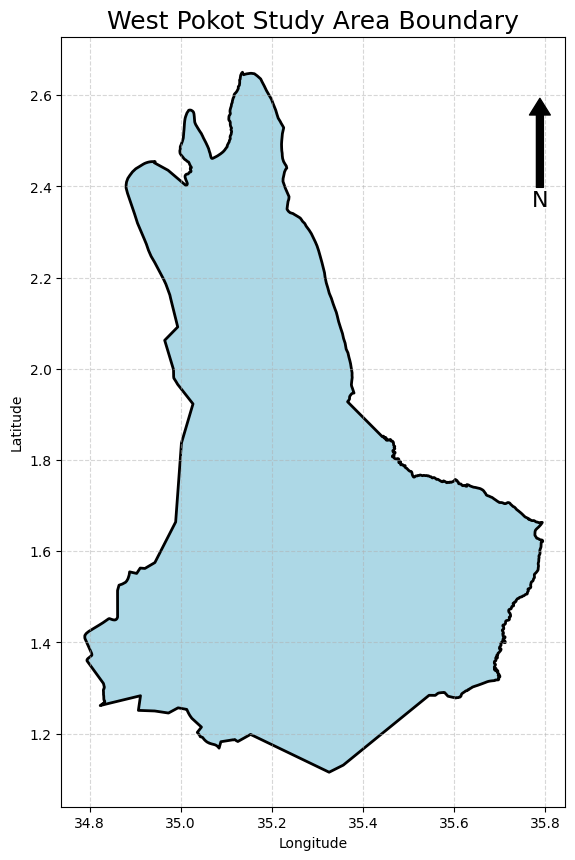

In [ ]:
#Plot study area
fig, ax = plt.subplots(figsize=(10,10))

gdf.plot(
    ax=ax,
    facecolor='lightblue',
    edgecolor='black',
    linewidth=2
)

# Title
ax.set_title(
    'West Pokot Study Area Boundary',
    fontsize=18
)

# Labels
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Grid
ax.grid(True, linestyle='--', alpha=0.5)

# North Arrow
ax.annotate(
    'N',
    xy=(0.95, 0.92),
    xytext=(0.95, 0.78),
    arrowprops=dict(
        facecolor='black',
        width=5,
        headwidth=15
    ),
    ha='center',
    fontsize=16,
    xycoords=ax.transAxes
)

plt.show()

In [ ]:
#Load DEM
dem_src = rasterio.open('/content/WestPokot_Elevation.tif')

# DEM array
dem_array = dem_src.read(1)

print(dem_src.crs)
print(dem_array.shape)

EPSG:4326
(5527, 3617)


In [ ]:
gdf = gdf.to_crs(dem_src.crs)

print("Study area reprojected.")

Study area reprojected.


/usr/local/lib/python3.12/dist-packages/matplotlib_scalebar/scalebar.py:457: UserWarning: Drawing scalebar on axes with unequal aspect ratio; either call ax.set_aspect(1) or suppress the warning with rotation='horizontal-only'.
  warnings.warn(


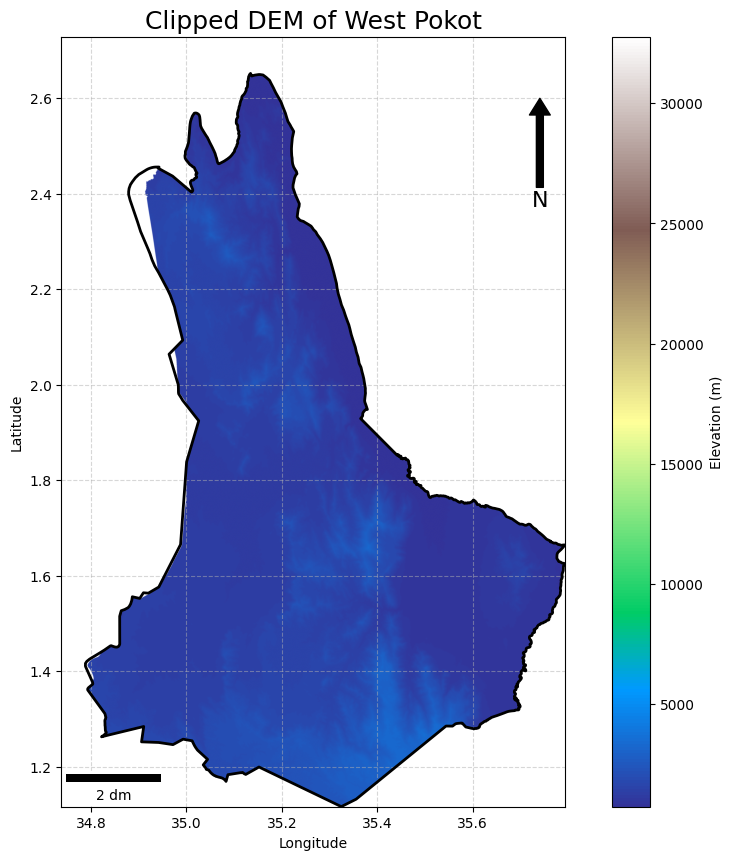

In [ ]:
# Open clipped DEM
dem = rasterio.open('WestPokot_Elevation.tif')

dem_array = dem.read(1)

# Extent
extent = [
    dem.bounds.left,
    dem.bounds.right,
    dem.bounds.bottom,
    dem.bounds.top
]

# Figure
fig, ax = plt.subplots(figsize=(12,10))

# Plot DEM
img = ax.imshow(
    dem_array,
    cmap='terrain',
    extent=extent,
    origin='upper'
)

# Plot boundary
gdf.boundary.plot(
    ax=ax,
    edgecolor='black',
    linewidth=2
)

# Colorbar
cbar = plt.colorbar(img, ax=ax)

cbar.set_label('Elevation (m)')

# Title
ax.set_title(
    'Clipped DEM of West Pokot',
    fontsize=18
)

# Labels
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Grid
ax.grid(True, linestyle='--', alpha=0.5)

# North Arrow
ax.annotate(
    'N',
    xy=(0.95, 0.92),
    xytext=(0.95, 0.78),
    arrowprops=dict(
        facecolor='black',
        width=5,
        headwidth=15
    ),
    ha='center',
    fontsize=16,
    xycoords=ax.transAxes
)

# Add Scale Bar
scalebar = ScaleBar(1, 'm', length_fraction=0.25, location='lower left') # 1 pixel = 1 meter, for example
ax.add_artist(scalebar)

plt.show()

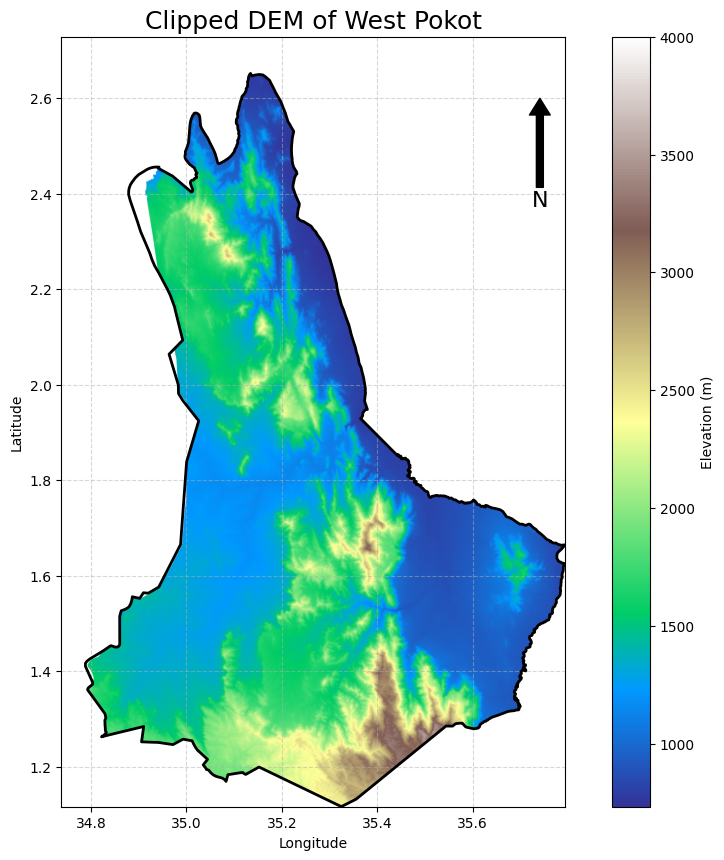

In [ ]:
# Open clipped DEM
dem = rasterio.open('WestPokot_Elevation.tif')

dem_array = dem.read(1)

# Extent
extent = [
    dem.bounds.left,
    dem.bounds.right,
    dem.bounds.bottom,
    dem.bounds.top
]

# Figure
fig, ax = plt.subplots(figsize=(12,10))

# Plot DEM with vmax = 4000 (values above appear as the top colour)
img = ax.imshow(
    dem_array,
    cmap='terrain',
    extent=extent,
    origin='upper',
    vmax=4000            # <<< CAP THE COLOUR SCALE AT 4000
    # vmin = 0           # Optionally set a lower bound (e.g., 0)
)

# Plot boundary
gdf.boundary.plot(
    ax=ax,
    edgecolor='black',
    linewidth=2
)

# Colorbar
cbar = plt.colorbar(img, ax=ax)
cbar.set_label('Elevation (m)')

# Optional: Add a note that values >4000 are clipped
#ax.text(0.02, 0.98, 'Note: Elevations >4000 m are shown with the highest colour',
        #transform=ax.transAxes, fontsize=9,
        #verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

# Title
ax.set_title(
    'Clipped DEM of West Pokot',
    fontsize=18
)

# Labels
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Grid
ax.grid(True, linestyle='--', alpha=0.5)

# North Arrow
ax.annotate(
    'N',
    xy=(0.95, 0.92),
    xytext=(0.95, 0.78),
    arrowprops=dict(
        facecolor='black',
        width=5,
        headwidth=15
    ),
    ha='center',
    fontsize=16,
    xycoords=ax.transAxes
)

plt.show()

In [ ]:
#Initialize Whitebox
wbt = WhiteboxTools()

wbt.set_working_dir('/content')

Decompressing WhiteboxTools_linux_musl.zip ...
WhiteboxTools package directory: /usr/local/lib/python3.12/dist-packages/whitebox


In [ ]:
#Generate Fill DEM Depressions
wbt.fill_depressions(
    'WestPokot_Elevation.tif',
    'filled_dem.tif'
)

print("Depressions filled.")

./whitebox_tools --run="FillDepressions" --wd="/content" --dem='WestPokot_Elevation.tif' --output='filled_dem.tif' --fix_flats -v --compress_rasters=False

******************************
* Welcome to FillDepressions *
* Powered by WhiteboxTools   *
* www.whiteboxgeo.com        *
******************************
Reading data...
Finding pit cells: 50%
Finding pit cells: 100%
Filling depressions: 0%
Filling depressions: 1%
Filling depressions: 2%
Filling depressions: 3%
Filling depressions: 4%
Filling depressions: 5%
Filling depressions: 6%
Filling depressions: 7%
Filling depressions: 8%
Filling depressions: 9%
Filling depressions: 10%
Filling depressions: 11%
Filling depressions: 12%
Filling depressions: 13%
Filling depressions: 14%
Filling depressions: 15%
Filling depressions: 16%
Filling depressions: 17%
Filling depressions: 18%
Filling depressions: 19%
Filling depressions: 20%
Filling depressions: 21%
Filling depressions: 22%
Filling depressions: 23%
Filling depressions: 24%
Filling dep

In [ ]:
#Generate flow direction
wbt.d8_pointer(
    'filled_dem.tif',
    'flow_direction.tif'
)

print("Flow direction generated.")

./whitebox_tools --run="D8Pointer" --wd="/content" --dem='filled_dem.tif' --output='flow_direction.tif' -v --compress_rasters=False

****************************
* Welcome to D8Pointer     *
* Powered by WhiteboxTools *
* www.whiteboxgeo.com      *
****************************
Reading data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progress: 43%
Progress: 44%
Progress: 45%
Progress: 46%
Progress: 47%
Progress: 48%
Progress: 49%
Progress: 50%
Pr

In [ ]:
#Generate flow accumulation
wbt.d8_flow_accumulation(
    'filled_dem.tif',
    'flow_accumulation.tif'
)

print("Flow accumulation generated.")

./whitebox_tools --run="D8FlowAccumulation" --wd="/content" --input='filled_dem.tif' --output='flow_accumulation.tif' --out_type=cells -v --compress_rasters=False

*********************************
* Welcome to D8FlowAccumulation *
* Powered by WhiteboxTools      *
* www.whiteboxgeo.com           *
*********************************
Reading data...
Flow directions: 0%
Flow directions: 1%
Flow directions: 2%
Flow directions: 3%
Flow directions: 4%
Flow directions: 5%
Flow directions: 6%
Flow directions: 7%
Flow directions: 8%
Flow directions: 9%
Flow directions: 10%
Flow directions: 11%
Flow directions: 12%
Flow directions: 13%
Flow directions: 14%
Flow directions: 15%
Flow directions: 16%
Flow directions: 17%
Flow directions: 18%
Flow directions: 19%
Flow directions: 20%
Flow directions: 21%
Flow directions: 22%
Flow directions: 23%
Flow directions: 24%
Flow directions: 25%
Flow directions: 26%
Flow directions: 27%
Flow directions: 28%
Flow directions: 29%
Flow directions: 30%
Flow dire

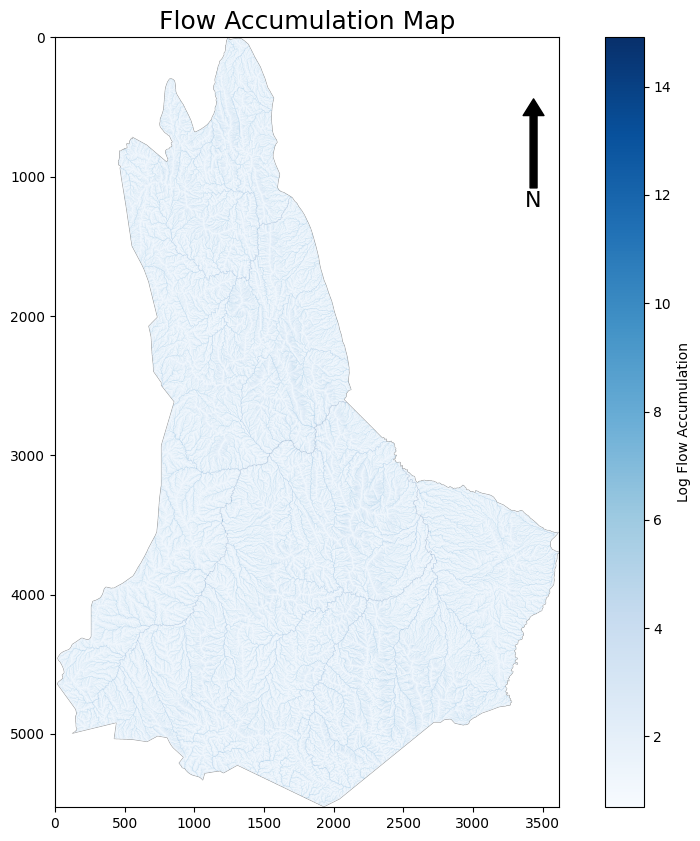

In [ ]:
flow = rasterio.open('flow_accumulation.tif')

flow_array = flow.read(1)

# Replace nodata values with NaN before log transform
flow_array[flow_array == flow.nodata] = np.nan

# Log transform
flow_log = np.log1p(flow_array)

fig, ax = plt.subplots(figsize=(12,10))

img = ax.imshow(
    flow_log,
    cmap='Blues'
)

# Colorbar
cbar = plt.colorbar(img, ax=ax)

cbar.set_label('Log Flow Accumulation')

# Title
ax.set_title(
    'Flow Accumulation Map',
    fontsize=18
)

# North Arrow
ax.annotate(
    'N',
    xy=(0.95, 0.92),
    xytext=(0.95, 0.78),
    arrowprops=dict(
        facecolor='black',
        width=5,
        headwidth=15
    ),
    ha='center',
    fontsize=16,
    xycoords=ax.transAxes
)

plt.show()

In [ ]:
#Extract stream network
wbt.extract_streams(
    'flow_accumulation.tif',
    'streams.tif',
    threshold=1000
)

print("Streams extracted.")

./whitebox_tools --run="ExtractStreams" --wd="/content" --flow_accum='flow_accumulation.tif' --output='streams.tif' --threshold='1000' -v --compress_rasters=False

*****************************
* Welcome to ExtractStreams *
* Powered by WhiteboxTools  *
* www.whiteboxgeo.com       *
*****************************
Reading data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progress: 43%
Progress: 44%
Progress: 45%
Progress: 46%
Progress: 47%
Progress

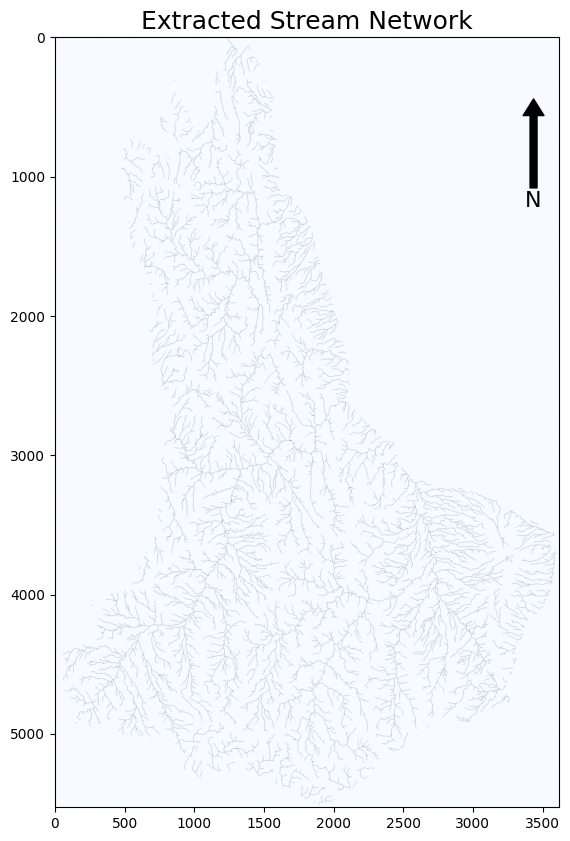

In [ ]:
#Plot stream network
streams = rasterio.open('streams.tif')

stream_array = streams.read(1)

fig, ax = plt.subplots(figsize=(12,10))

ax.imshow(
    stream_array,
    cmap='Blues'
)

ax.set_title(
    'Extracted Stream Network',
    fontsize=18
)

# North Arrow
ax.annotate(
    'N',
    xy=(0.95, 0.92),
    xytext=(0.95, 0.78),
    arrowprops=dict(
        facecolor='black',
        width=5,
        headwidth=15
    ),
    ha='center',
    fontsize=16,
    xycoords=ax.transAxes
)

plt.show()

In [ ]:
#Generate pourpoint automatically
# Find max accumulation
max_index = np.unravel_index(
    np.nanargmax(flow_array),
    flow_array.shape
)

row, col = max_index

# Coordinates
x, y = flow.xy(row, col)

print(x, y)

35.37166666666666 1.9219444444444376


In [ ]:
#Create pourpoint shapefile
point = Point(x, y)

pour_gdf = gpd.GeoDataFrame(
    {'id':[1]},
    geometry=[point],
    crs=gdf.crs
)

pour_gdf.to_file('pour_point.shp')

print("Pour point created.")

Pour point created.


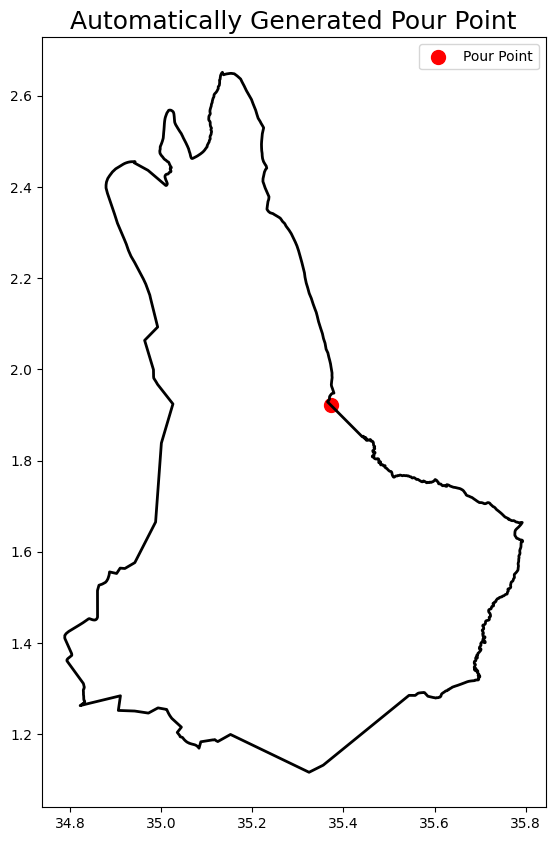

In [ ]:
#PLot pourpoint
fig, ax = plt.subplots(figsize=(12,10))

gdf.boundary.plot(
    ax=ax,
    edgecolor='black',
    linewidth=2
)

pour_gdf.plot(
    ax=ax,
    color='red',
    markersize=100,
    label='Pour Point'
)

ax.set_title(
    'Automatically Generated Pour Point',
    fontsize=18
)

ax.legend()

plt.show()

In [ ]:
#Snap pourpoint to stream
wbt.jenson_snap_pour_points(
    pour_pts='pour_point.shp',
    streams='streams.tif',
    output='snapped_pour_point.shp',
    snap_dist=100
)

print("Pour point snapped.")

./whitebox_tools --run="JensonSnapPourPoints" --wd="/content" --pour_pts='pour_point.shp' --streams='streams.tif' --output='snapped_pour_point.shp' --snap_dist='100' -v --compress_rasters=False

***********************************
* Welcome to JensonSnapPourPoints *
* Powered by WhiteboxTools        *
* www.whiteboxgeo.com             *
***********************************
Reading data...
Progress: 0%
Saving data...
Output file written
Elapsed Time (excluding I/O): 8min 14.606s
Pour point snapped.


In [ ]:
#Delineate watershed
wbt.watershed(
    d8_pntr='flow_direction.tif',
    pour_pts='snapped_pour_point.shp',
    output='watershed.tif'
)

print("Watershed delineated.")

./whitebox_tools --run="Watershed" --wd="/content" --d8_pntr='flow_direction.tif' --pour_pts='snapped_pour_point.shp' --output='watershed.tif' -v --compress_rasters=False

****************************
* Welcome to Watershed     *
* Powered by WhiteboxTools *
* www.whiteboxgeo.com      *
****************************
Reading data...
Locating pour points: 0%
Initializing: 1%
Initializing: 2%
Initializing: 3%
Initializing: 4%
Initializing: 5%
Initializing: 6%
Initializing: 7%
Initializing: 8%
Initializing: 9%
Initializing: 10%
Initializing: 11%
Initializing: 12%
Initializing: 13%
Initializing: 14%
Initializing: 15%
Initializing: 16%
Initializing: 17%
Initializing: 18%
Initializing: 19%
Initializing: 20%
Initializing: 21%
Initializing: 22%
Initializing: 23%
Initializing: 24%
Initializing: 25%
Initializing: 26%
Initializing: 27%
Initializing: 28%
Initializing: 29%
Initializing: 30%
Initializing: 31%
Initializing: 32%
Initializing: 33%
Initializing: 34%
Initializing: 35%
Initializing: 36%
Ini

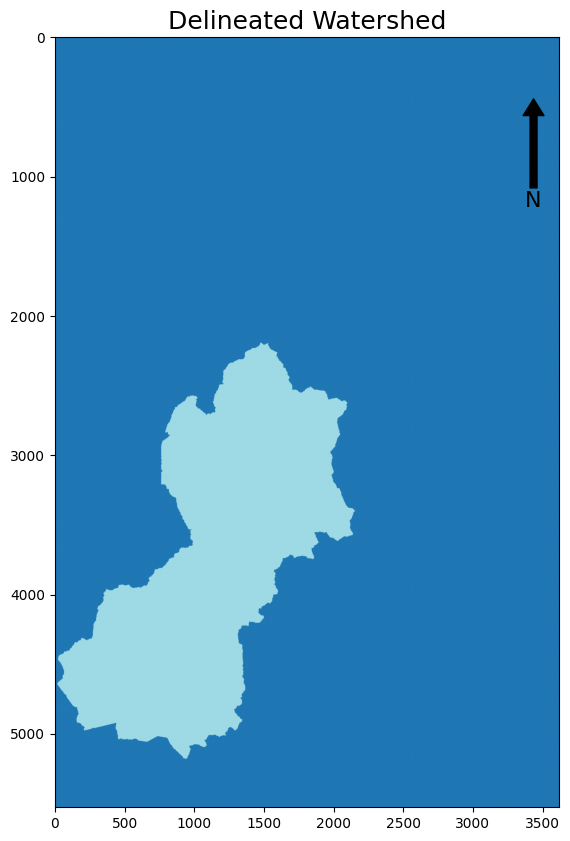

In [ ]:
#Plot watershed
watershed = rasterio.open('watershed.tif')

watershed_array = watershed.read(1)

fig, ax = plt.subplots(figsize=(12,10))

img = ax.imshow(
    watershed_array,
    cmap='tab20'
)

ax.set_title(
    'Delineated Watershed',
    fontsize=18
)

# North Arrow
ax.annotate(
    'N',
    xy=(0.95, 0.92),
    xytext=(0.95, 0.78),
    arrowprops=dict(
        facecolor='black',
        width=5,
        headwidth=15
    ),
    ha='center',
    fontsize=16,
    xycoords=ax.transAxes
)

plt.show()

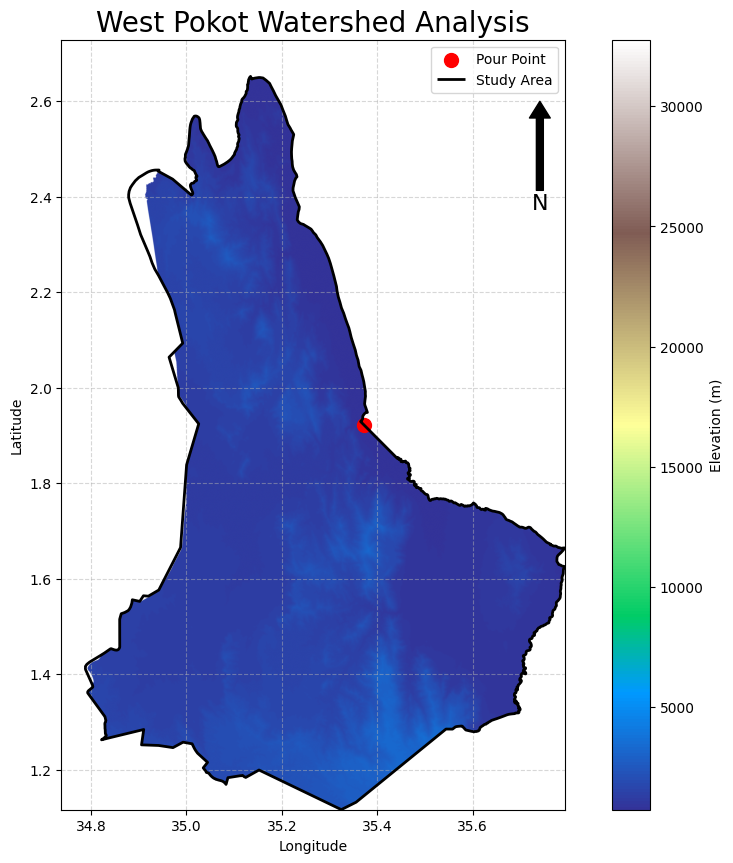

In [ ]:
fig, ax = plt.subplots(figsize=(12,10))

# DEM
img = ax.imshow(
    dem_array,
    cmap='terrain',
    extent=extent,
    origin='upper'
)

# Watershed
pour_gdf.plot(
    ax=ax,
    color='red',
    markersize=100,
    label='Pour Point'
)

# Study Area
gdf.boundary.plot(
    ax=ax,
    edgecolor='black',
    linewidth=2,
    label='Study Area'
)

# Colorbar
cbar = plt.colorbar(img, ax=ax)

cbar.set_label('Elevation (m)')

# Title
ax.set_title(
    'West Pokot Watershed Analysis',
    fontsize=20
)

# Labels
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Legend
ax.legend()

# Grid
ax.grid(True, linestyle='--', alpha=0.5)

# North Arrow
ax.annotate(
    'N',
    xy=(0.95, 0.92),
    xytext=(0.95, 0.78),
    arrowprops=dict(
        facecolor='black',
        width=5,
        headwidth=15
    ),
    ha='center',
    fontsize=16,
    xycoords=ax.transAxes
)

plt.show()

In [ ]:
from rasterio.features import shapes
from shapely.geometry import shape
import geopandas as gpd
import numpy as np
import rasterio

# Open watershed raster
watershed_src = rasterio.open('watershed.tif')

# Read raster
watershed_array = watershed_src.read(1)

# Create mask
mask = watershed_array > 0

# Convert raster to polygon
results = (
    {'properties': {'value': v}, 'geometry': s}
    for s, v in shapes(
        watershed_array.astype(np.int32),
        mask=mask,
        transform=watershed_src.transform
    )
)

# Create list
geoms = list(results)

# Create GeoDataFrame
watershed_gdf = gpd.GeoDataFrame.from_features(geoms)

# Set CRS
watershed_gdf.crs = gdf.crs

print("Watershed polygon created.")

Watershed polygon created.


In [ ]:
# Keep largest polygon only
watershed_gdf = watershed_gdf[
    watershed_gdf.area == watershed_gdf.area.max()
]

print("Largest watershed polygon retained.")

Largest watershed polygon retained.


/tmp/ipykernel_5278/3822385757.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  watershed_gdf.area == watershed_gdf.area.max()


/tmp/ipykernel_5278/429668329.py:44: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


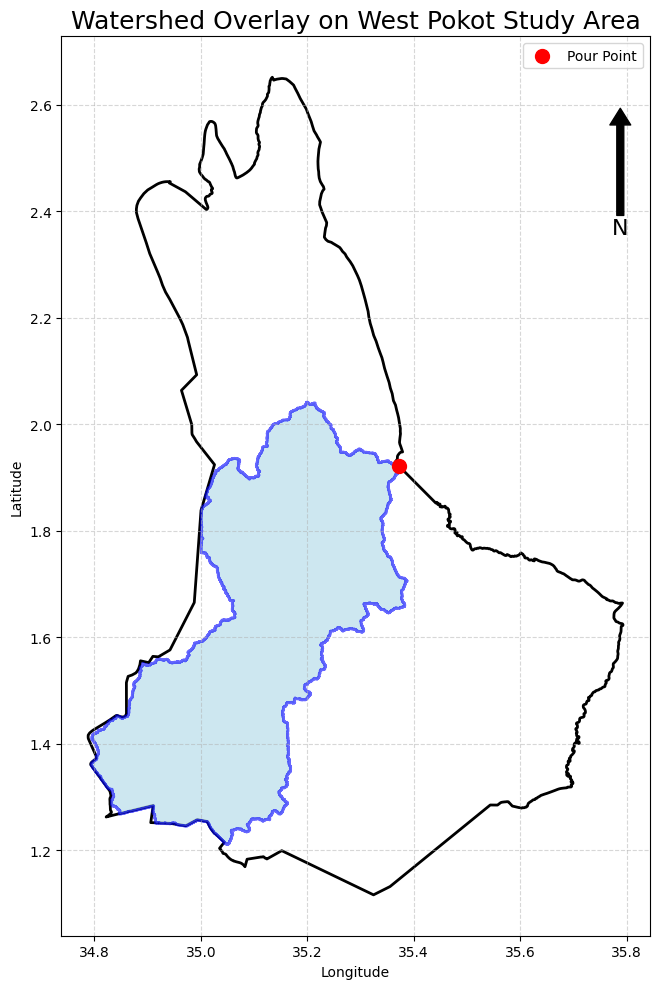

In [ ]:
import matplotlib.pyplot as plt

# Create figure
fig, ax = plt.subplots(figsize=(12,10))

# Plot study area
gdf.plot(
    ax=ax,
    facecolor='none',
    edgecolor='black',
    linewidth=2,
    label='Study Area'
)

# Plot watershed
watershed_gdf.plot(
    ax=ax,
    facecolor='lightblue',
    edgecolor='blue',
    alpha=0.6,
    linewidth=2,
    label='Watershed'
)

# Plot pour point
pour_gdf.plot(
    ax=ax,
    color='red',
    markersize=100,
    label='Pour Point'
)

# Title
ax.set_title(
    'Watershed Overlay on West Pokot Study Area',
    fontsize=18
)

# Labels
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Legend
ax.legend()

# Grid
ax.grid(
    True,
    linestyle='--',
    alpha=0.5
)

# North Arrow
ax.annotate(
    'N',
    xy=(0.95, 0.92),
    xytext=(0.95, 0.78),
    arrowprops=dict(
        facecolor='black',
        width=5,
        headwidth=15
    ),
    ha='center',
    fontsize=16,
    xycoords=ax.transAxes
)

# Tight layout
plt.tight_layout()

# Show plot
plt.show()

In [ ]:
#Convert streams to raster
from rasterio.features import shapes
from shapely.geometry import shape
import geopandas as gpd
import rasterio
import numpy as np

# Open streams raster
streams_src = rasterio.open('streams.tif')

# Read stream raster
streams_array = streams_src.read(1)

# Create stream mask
stream_mask = streams_array > 0

# Convert raster to vector
stream_shapes = (
    {'properties': {'value': v}, 'geometry': s}
    for s, v in shapes(
        streams_array.astype(np.int32),
        mask=stream_mask,
        transform=streams_src.transform
    )
)

# Convert to list
stream_geoms = list(stream_shapes)

# Create GeoDataFrame
streams_gdf = gpd.GeoDataFrame.from_features(stream_geoms)

# Assign CRS
streams_gdf.crs = gdf.crs

print("Streams converted to vector.")

Streams converted to vector.


In [ ]:
# Remove tiny polygons
streams_gdf = streams_gdf[
    streams_gdf.area > streams_gdf.area.mean() * 0.1
]

print("Small stream artifacts removed.")

Small stream artifacts removed.


/tmp/ipykernel_5278/2774938568.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  streams_gdf.area > streams_gdf.area.mean() * 0.1


/tmp/ipykernel_5278/203606137.py:73: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


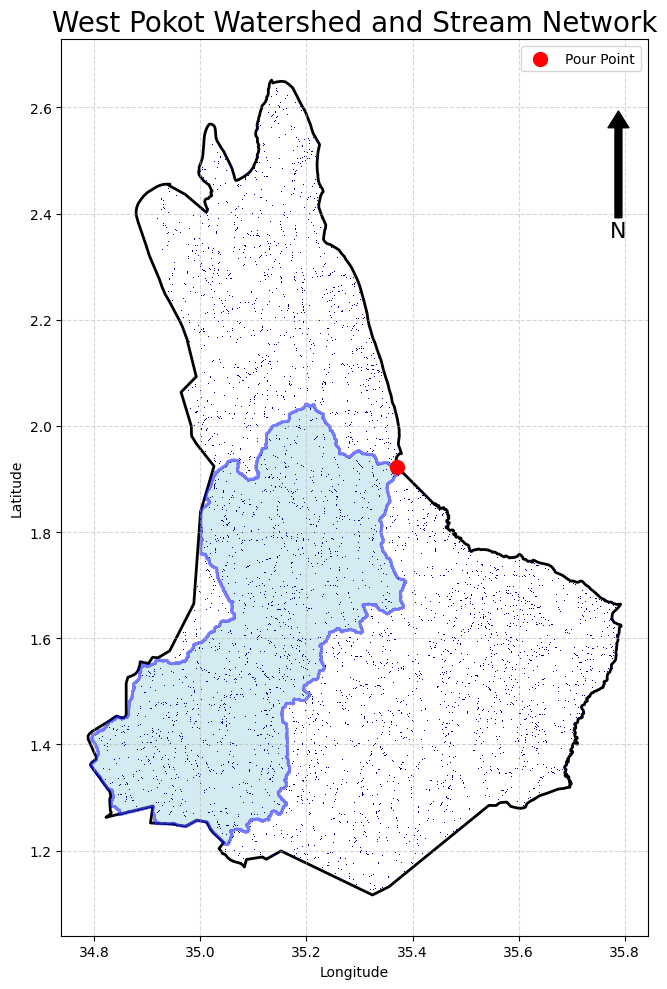

In [ ]:
import matplotlib.pyplot as plt

# Create figure
fig, ax = plt.subplots(figsize=(12,10))

# -----------------------------------------
# PLOT STUDY AREA
# -----------------------------------------

gdf.plot(
    ax=ax,
    facecolor='none',
    edgecolor='black',
    linewidth=2,
    label='Study Area'
)

# -----------------------------------------
# PLOT WATERSHED
# -----------------------------------------

watershed_gdf.plot(
    ax=ax,
    facecolor='lightblue',
    edgecolor='blue',
    alpha=0.5,
    linewidth=2,
    label='Watershed'
)

# -----------------------------------------
# PLOT STREAMS
# -----------------------------------------

streams_gdf.plot(
    ax=ax,
    color='darkblue',
    linewidth=1,
    label='Extracted Streams'
)

# -----------------------------------------
# PLOT POUR POINT
# -----------------------------------------

pour_gdf.plot(
    ax=ax,
    color='red',
    markersize=100,
    label='Pour Point'
)

# -----------------------------------------
# TITLE
# -----------------------------------------

ax.set_title(
    'West Pokot Watershed and Stream Network',
    fontsize=20
)

# -----------------------------------------
# AXIS LABELS
# -----------------------------------------

ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# -----------------------------------------
# LEGEND
# -----------------------------------------

ax.legend()

# -----------------------------------------
# GRID
# -----------------------------------------

ax.grid(
    True,
    linestyle='--',
    alpha=0.5
)

# -----------------------------------------
# NORTH ARROW
# -----------------------------------------

ax.annotate(
    'N',
    xy=(0.95, 0.92),
    xytext=(0.95, 0.78),
    arrowprops=dict(
        facecolor='black',
        width=5,
        headwidth=15
    ),
    ha='center',
    fontsize=16,
    xycoords=ax.transAxes
)

# -----------------------------------------
# TIGHT LAYOUT
# -----------------------------------------

plt.tight_layout()

# -----------------------------------------
# SHOW MAP
# -----------------------------------------

plt.show()

/tmp/ipykernel_5278/903196364.py:75: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


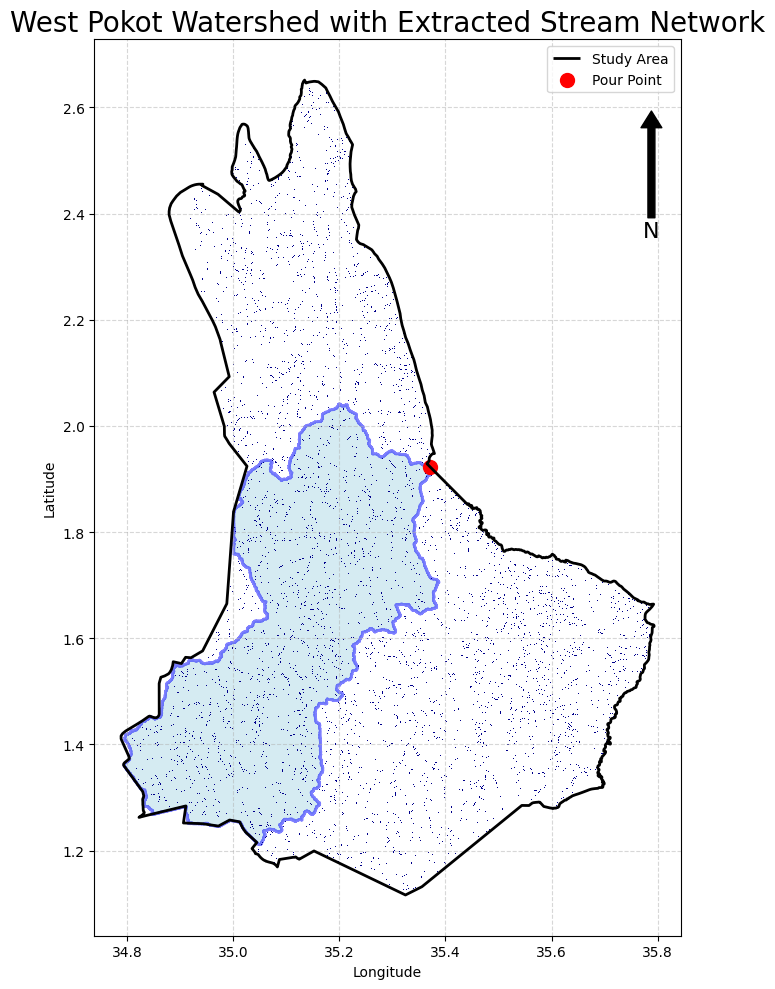

In [ ]:
import matplotlib.pyplot as plt

# -----------------------------------------
# CREATE FIGURE
# -----------------------------------------

fig, ax = plt.subplots(figsize=(12,10))

# -----------------------------------------
# PLOT STUDY AREA BOUNDARY
# -----------------------------------------

gdf.boundary.plot(
    ax=ax,
    edgecolor='black',
    linewidth=2,
    label='Study Area'
)

# -----------------------------------------
# PLOT WATERSHED
# -----------------------------------------

watershed_gdf.plot(
    ax=ax,
    facecolor='lightblue',
    edgecolor='blue',
    alpha=0.5,
    linewidth=2,
    label='Watershed'
)

# -----------------------------------------
# PLOT EXTRACTED STREAM NETWORK
# -----------------------------------------

streams_gdf.plot(
    ax=ax,
    color='darkblue',
    linewidth=1,
    label='Extracted Streams'
)

# -----------------------------------------
# PLOT POUR POINT
# -----------------------------------------

pour_gdf.plot(
    ax=ax,
    color='red',
    markersize=100,
    label='Pour Point'
)

# -----------------------------------------
# TITLE
# -----------------------------------------

ax.set_title(
    'West Pokot Watershed with Extracted Stream Network',
    fontsize=20
)

# -----------------------------------------
# AXIS LABELS
# -----------------------------------------

ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# -----------------------------------------
# LEGEND
# -----------------------------------------

ax.legend()

# -----------------------------------------
# GRID
# -----------------------------------------

ax.grid(
    True,
    linestyle='--',
    alpha=0.5
)

# -----------------------------------------
# NORTH ARROW
# -----------------------------------------

ax.annotate(
    'N',
    xy=(0.95, 0.92),
    xytext=(0.95, 0.78),
    arrowprops=dict(
        facecolor='black',
        width=5,
        headwidth=15
    ),
    ha='center',
    fontsize=16,
    xycoords=ax.transAxes
)

# -----------------------------------------
# TIGHT LAYOUT
# -----------------------------------------

plt.tight_layout()

# -----------------------------------------
# SHOW MAP
# -----------------------------------------

plt.show()

In [ ]:
wbt.extract_streams(
    flow_accum='flow_accumulation.tif',
    output='streams_5000.tif',
    threshold=5000
)

print("Streams extracted with higher threshold.")

./whitebox_tools --run="ExtractStreams" --wd="/content" --flow_accum='flow_accumulation.tif' --output='streams_5000.tif' --threshold='5000' -v --compress_rasters=False

*****************************
* Welcome to ExtractStreams *
* Powered by WhiteboxTools  *
* www.whiteboxgeo.com       *
*****************************
Reading data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progress: 43%
Progress: 44%
Progress: 45%
Progress: 46%
Progress: 47%
Pro

In [ ]:
from rasterio.features import shapes
import geopandas as gpd
import rasterio
import numpy as np

# Open raster
streams_src = rasterio.open('streams_5000.tif')

# Read raster
streams_array = streams_src.read(1)

# Create mask
stream_mask = streams_array > 0

# Convert raster to vector
stream_shapes = (
    {'properties': {'value': v}, 'geometry': s}
    for s, v in shapes(
        streams_array.astype(np.int32),
        mask=stream_mask,
        transform=streams_src.transform
    )
)

# Create GeoDataFrame
streams_gdf = gpd.GeoDataFrame.from_features(list(stream_shapes))

# Set CRS
streams_gdf.crs = gdf.crs

print("Stream vectors created.")

Stream vectors created.


/tmp/ipykernel_5278/1712503339.py:50: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


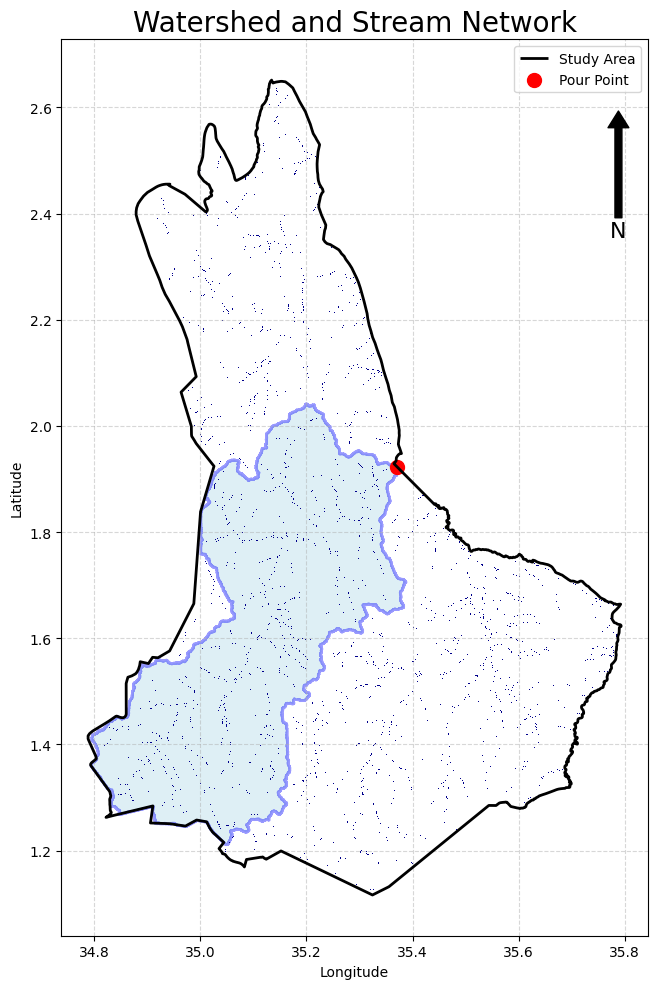

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12,10))

# Study area
gdf.boundary.plot(
    ax=ax,
    edgecolor='black',
    linewidth=2,
    label='Study Area'
)

# Watershed
watershed_gdf.plot(
    ax=ax,
    facecolor='lightblue',
    edgecolor='blue',
    alpha=0.4,
    linewidth=2,
    label='Watershed'
)

# Stream network
streams_gdf.plot(
    ax=ax,
    color='darkblue',
    linewidth=1.5,
    label='Stream Network'
)

# Pour point
pour_gdf.plot(
    ax=ax,
    color='red',
    markersize=100,
    label='Pour Point'
)

# Title
ax.set_title(
    'Watershed and Stream Network',
    fontsize=20
)

# Labels
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Legend
ax.legend()

# Grid
ax.grid(True, linestyle='--', alpha=0.5)

# North arrow
ax.annotate(
    'N',
    xy=(0.95, 0.92),
    xytext=(0.95, 0.78),
    arrowprops=dict(
        facecolor='black',
        width=5,
        headwidth=15
    ),
    ha='center',
    fontsize=16,
    xycoords=ax.transAxes
)

plt.tight_layout()

plt.show()

/tmp/ipykernel_5278/1610123063.py:82: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc='upper right', frameon=True, shadow=True)


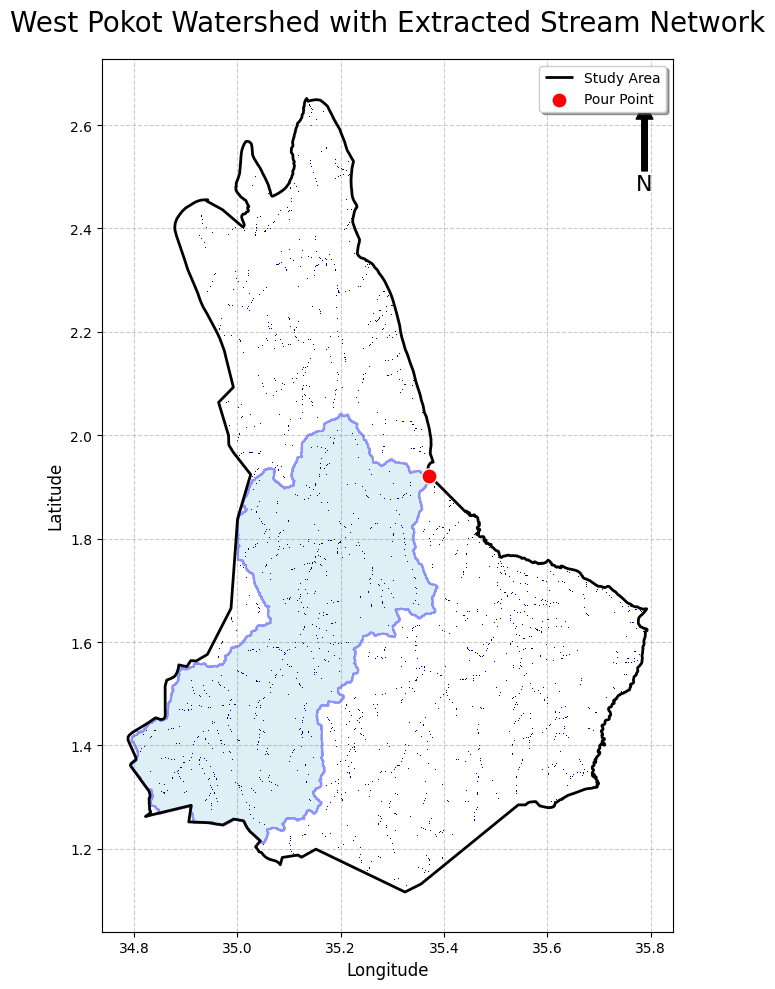

In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd

# -----------------------------------------
# CREATE FIGURE
# -----------------------------------------

fig, ax = plt.subplots(figsize=(12,10))

# -----------------------------------------
# PLOT STUDY AREA BOUNDARY
# -----------------------------------------

gdf.boundary.plot(
    ax=ax,
    edgecolor='black',
    linewidth=2,
    label='Study Area'
)

# -----------------------------------------
# PLOT WATERSHED
# -----------------------------------------

watershed_gdf.plot(
    ax=ax,
    facecolor='lightblue',
    edgecolor='blue',
    alpha=0.4,
    linewidth=1.5,
    label='Watershed'
)

# -----------------------------------------
# PLOT EXTRACTED STREAM NETWORK
# -----------------------------------------

# NOTE: If streams_gdf is still showing dots, check if:
# type(streams_gdf.geometry.iloc[0]) is Point.
# If so, you must vectorize your raster to Polylines first.

streams_gdf.plot(
    ax=ax,
    color='darkblue',
    linewidth=1.2,      # Slightly thicker to connect visual gaps
    capstyle='round',   # Rounds the ends of lines to make them look fluid
    joinstyle='round',  # Smoothes the joints between line segments
    label='Extracted Streams'
)

# -----------------------------------------
# PLOT POUR POINT
# -----------------------------------------

pour_gdf.plot(
    ax=ax,
    color='red',
    markersize=120,
    edgecolor='white', # Added for better visibility against blue
    label='Pour Point',
    zorder=5           # Ensures point stays on top of stream lines
)

# -----------------------------------------
# TITLE & LABELS
# -----------------------------------------

ax.set_title(
    'West Pokot Watershed with Extracted Stream Network',
    fontsize=20,
    pad=20
)

ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)

# -----------------------------------------
# LEGEND
# -----------------------------------------

# Using frameon=True helps the legend stand out if it overlaps data
ax.legend(loc='upper right', frameon=True, shadow=True)

# -----------------------------------------
# GRID
# -----------------------------------------

ax.grid(
    True,
    linestyle='--',
    alpha=0.4,
    color='gray'
)

# -----------------------------------------
# NORTH ARROW
# -----------------------------------------

ax.annotate(
    'N',
    xy=(0.95, 0.95),
    xytext=(0.95, 0.85),
    arrowprops=dict(
        facecolor='black',
        width=4,
        headwidth=12
    ),
    ha='center',
    fontsize=16,
    xycoords=ax.transAxes
)

# -----------------------------------------
# FINAL LAYOUT
# -----------------------------------------

plt.tight_layout()
plt.show()

**CORRECT SOLUTION- RASTER STREAM LINES**

In [ ]:
# -----------------------------------------
# CONVERT STREAM RASTER TO VECTOR LINES
# -----------------------------------------

wbt.raster_streams_to_vector(
    streams='streams_5000.tif',
    d8_pntr='flow_direction.tif',
    output='streams_vector.shp'
)

print("Vector stream network created.")

./whitebox_tools --run="RasterStreamsToVector" --wd="/content" --streams='streams_5000.tif' --d8_pntr='flow_direction.tif' --output='streams_vector.shp' -v --compress_rasters=False

************************************
* Welcome to RasterStreamsToVector *
* Powered by WhiteboxTools         *
* www.whiteboxgeo.com              *
************************************
Reading pointer data...
Reading streams data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progres

In [ ]:
# -----------------------------------------
# LOAD VECTOR STREAMS
# -----------------------------------------

streams_gdf = gpd.read_file('streams_vector.shp')
streams_gdf.crs = gdf.crs

print(streams_gdf.geom_type.unique())

['LineString']


/tmp/ipykernel_5278/2113996292.py:49: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


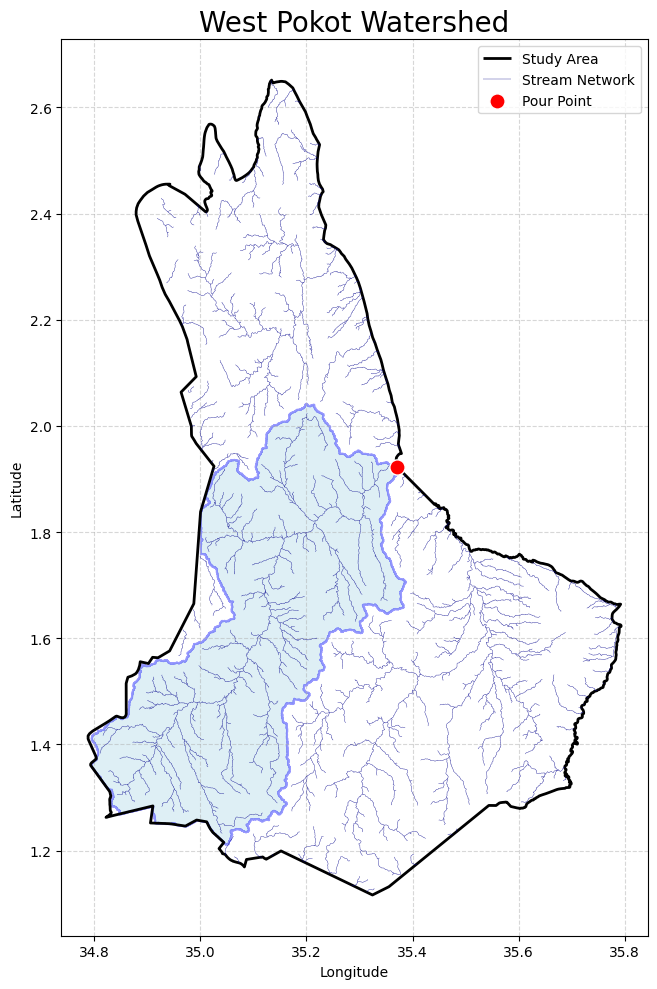

In [ ]:
#Plot proper stream network
fig, ax = plt.subplots(figsize=(12,10))

# Study area
gdf.boundary.plot(
    ax=ax,
    edgecolor='black',
    linewidth=2,
    label='Study Area'
)

# Watershed
watershed_gdf.plot(
    ax=ax,
    facecolor='lightblue',
    edgecolor='blue',
    alpha=0.4,
    linewidth=1.5,
    label='Watershed'
)

# STREAM LINES
streams_gdf.plot(
    ax=ax,
    color='darkblue',
    linewidth=0.250,
    label='Stream Network'
)

# Pour point
pour_gdf.plot(
    ax=ax,
    color='red',
    markersize=120,
    edgecolor='white',
    label='Pour Point',
    zorder=5
)

# Title
ax.set_title(
    'West Pokot Watershed',
    fontsize=20
)

ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

ax.legend()

ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Watershed Characterization**

In [ ]:
# Watershed Area
# Reproject to metric CRS first
watershed_metric = watershed_gdf.to_crs(epsg=21037)

# Area in square kilometers
watershed_area = watershed_metric.area.sum() / 1e6

print("Watershed Area (km²):", watershed_area)

Watershed Area (km²): 2844.8496022576637


In [ ]:
# Stream length
streams_metric = streams_gdf.to_crs(epsg=21037)

total_stream_length = streams_metric.length.sum() / 1000

print("Total Stream Length (km):", total_stream_length)

Total Stream Length (km): 3330.3876638506763


In [ ]:
# Drainage Density
drainage_density = total_stream_length / watershed_area

print("Drainage Density:", drainage_density, "km/km²")

Drainage Density: 1.1706726644556855 km/km²


**Slope for Watershed**

In [ ]:
from rasterio.mask import mask
import rasterio

# Open DEM
dem_src = rasterio.open('filled_dem.tif')

# Clip DEM using watershed polygon
clipped_dem, clipped_transform = mask(
    dem_src,
    watershed_gdf.geometry,
    crop=True
)

# Update metadata
clipped_meta = dem_src.meta.copy()

clipped_meta.update({
    "driver": "GTiff",
    "height": clipped_dem.shape[1],
    "width": clipped_dem.shape[2],
    "transform": clipped_transform
})

# Save clipped DEM
with rasterio.open(
    'watershed_dem.tif',
    'w',
    **clipped_meta
) as dest:
    dest.write(clipped_dem)

print("DEM clipped to watershed.")

DEM clipped to watershed.


In [ ]:
# Generate slope fo watershed DEM
wbt.slope(
    dem='watershed_dem.tif',
    output='watershed_slope.tif',
    units='degrees'
)

print("Watershed slope generated.")

./whitebox_tools --run="Slope" --wd="/content" --dem='watershed_dem.tif' --output='watershed_slope.tif' --units=degrees -v --compress_rasters=False

****************************
* Welcome to Slope         *
* Powered by WhiteboxTools *
* www.whiteboxgeo.com      *
****************************
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progress: 43%
Progress: 44%
Progress: 45%
Progress: 46%
Progress: 47%
Progress: 48%
Progress: 49%
Progress: 50%
Pr

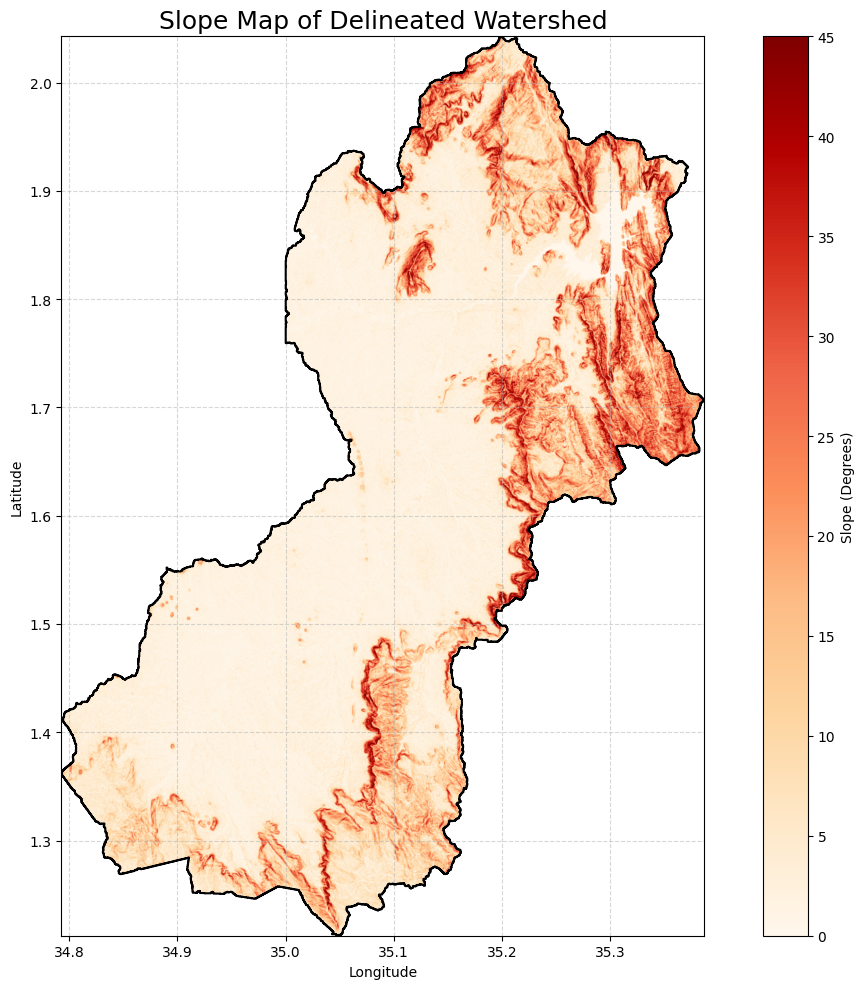

In [ ]:
#Plot watershed slope
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# Open slope raster
slope_src = rasterio.open('watershed_slope.tif')

# Read slope
slope_array = slope_src.read(1)

# Remove invalid values
slope_array = np.where(
    (slope_array < 0) | (slope_array > 90),
    np.nan,
    slope_array
)

# Spatial extent
extent = [
    slope_src.bounds.left,
    slope_src.bounds.right,
    slope_src.bounds.bottom,
    slope_src.bounds.top
]

# Create figure
fig, ax = plt.subplots(figsize=(12,10))

# Plot slope
img = ax.imshow(
    slope_array,
    cmap='OrRd',
    extent=extent,
    origin='upper',
    interpolation='bilinear',
    vmin=0,
    vmax=45
)

# Watershed boundary
watershed_gdf.boundary.plot(
    ax=ax,
    edgecolor='black',
    linewidth=1.5
)

# Colorbar
cbar = plt.colorbar(img, ax=ax)
cbar.set_label('Slope (Degrees)')

# Title
ax.set_title(
    'Slope Map of Delineated Watershed',
    fontsize=18
)

# Labels
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Grid
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Stream order
# Generate stream order raster
wbt.strahler_stream_order(
    d8_pntr='flow_direction.tif',
    streams='streams_5000.tif',
    output='stream_order.tif'
)

print("Stream order generated.")

./whitebox_tools --run="StrahlerStreamOrder" --wd="/content" --d8_pntr='flow_direction.tif' --streams='streams_5000.tif' --output='stream_order.tif' -v --compress_rasters=False

**********************************
* Welcome to StrahlerStreamOrder *
* Powered by WhiteboxTools       *
* www.whiteboxgeo.com            *
**********************************
Reading pointer data...
Reading streams data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progres

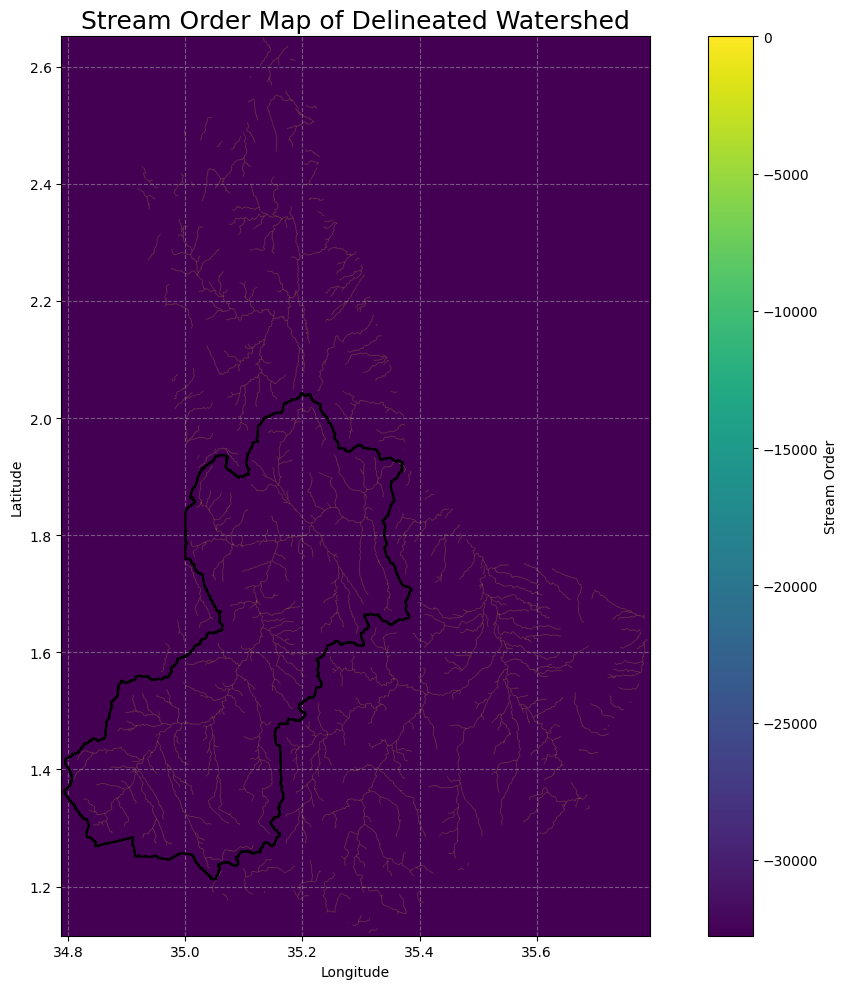

In [ ]:
# Visualize stream order
import rasterio
import matplotlib.pyplot as plt

# Open stream order raster
stream_order_src = rasterio.open('stream_order.tif')

# Read raster
stream_order = stream_order_src.read(1)

# Extent
extent = [
    stream_order_src.bounds.left,
    stream_order_src.bounds.right,
    stream_order_src.bounds.bottom,
    stream_order_src.bounds.top
]

# Plot
fig, ax = plt.subplots(figsize=(12,10))

img = ax.imshow(
    stream_order,
    cmap='viridis',
    extent=extent,
    origin='upper'
)

# Watershed boundary
watershed_gdf.boundary.plot(
    ax=ax,
    edgecolor='black',
    linewidth=1.5
)

# Colorbar
cbar = plt.colorbar(img, ax=ax)
cbar.set_label('Stream Order')

# Title
ax.set_title(
    'Stream Order Map of Delineated Watershed',
    fontsize=18
)

# Labels
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Grid
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

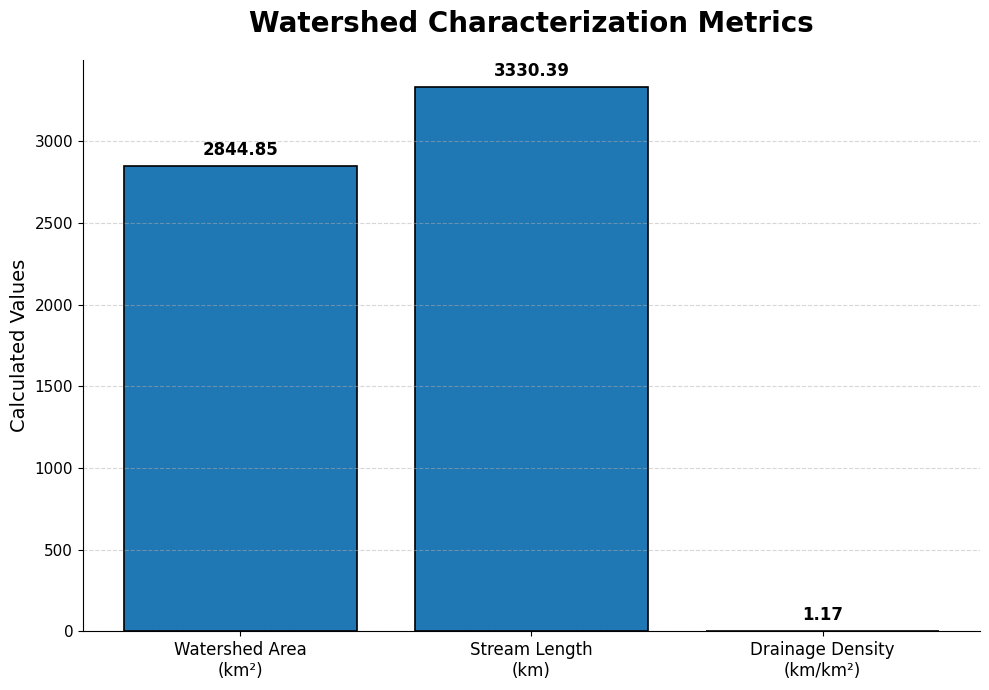

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------------------
# WATERSHED CHARACTERISTICS
# -----------------------------------------

# Replace these with your actual calculated values
watershed_area = watershed_area          # km²
stream_length = total_stream_length            # km
drainage_density = drainage_density      # km/km²

# -----------------------------------------
# DATA FOR VISUALIZATION
# -----------------------------------------

parameters = [
    'Watershed Area\n(km²)',
    'Stream Length\n(km)',
    'Drainage Density\n(km/km²)'
]

values = [
    watershed_area,
    stream_length,
    drainage_density
]

# -----------------------------------------
# CREATE FIGURE
# -----------------------------------------

fig, ax = plt.subplots(figsize=(10,7))

# Bar plot
bars = ax.bar(
    parameters,
    values,
    edgecolor='black',
    linewidth=1.2
)

# -----------------------------------------
# VALUE LABELS
# -----------------------------------------

for bar in bars:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width()/2,
        height + (max(values) * 0.02),
        f'{height:.2f}',
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

# -----------------------------------------
# TITLE
# -----------------------------------------

ax.set_title(
    'Watershed Characterization Metrics',
    fontsize=20,
    pad=20,
    fontweight='bold'
)

# -----------------------------------------
# AXIS LABELS
# -----------------------------------------

ax.set_ylabel(
    'Calculated Values',
    fontsize=14
)

# -----------------------------------------
# GRID
# -----------------------------------------

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.5
)

# -----------------------------------------
# STYLE IMPROVEMENTS
# -----------------------------------------

# Remove top/right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Improve tick labels
ax.tick_params(
    axis='x',
    labelsize=12
)

ax.tick_params(
    axis='y',
    labelsize=11
)

# -----------------------------------------
# FINAL LAYOUT
# -----------------------------------------

plt.tight_layout()

# Save figure (optional)
plt.savefig(
    'watershed_characteristics.png',
    dpi=300,
    bbox_inches='tight'
)

# Show plot
plt.show()